In [1]:
import os
import cv2
import numpy as np
import glob
import tensorflow as tf
from tensorflow.keras import layers, Model, backend as K
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
IMG_SIZE = 256
BATCH_SIZE = 16

from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/Dataset_BUSI_with_GT'

Mounted at /content/drive


In [3]:
def load_busi_data(base_path):
    images = []
    masks = []
    folders = ['benign', 'malignant', 'normal']

    for folder in folders:
        folder_path = os.path.join(base_path, folder)
        if not os.path.exists(folder_path):
            continue


        image_files = glob.glob(os.path.join(folder_path, "*[0-9]).png"))


        if folder == 'normal':
            np.random.shuffle(image_files)
            image_files = image_files[:int(len(image_files) * 0.3)]

        print(f"Loading {len(image_files)} images from {folder}...")

        for img_path in image_files:

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


            mask_pattern = img_path.replace(".png", "_mask*")
            mask_files = glob.glob(mask_pattern)


            merged_mask = np.zeros((img.shape[0], img.shape[1]), dtype=np.float32)


            if len(mask_files) > 0:
                for m_path in mask_files:
                    m = cv2.imread(m_path, 0)
                    if m is not None:
                        merged_mask = np.maximum(merged_mask, m)


            img_res = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE).numpy()
            mask_res = tf.image.resize_with_pad(np.expand_dims(merged_mask, -1), IMG_SIZE, IMG_SIZE).numpy()


            images.append(img_res / 255.0)
            masks.append(mask_res / 255.0)

    return np.array(images, dtype="float32"), np.array(masks, dtype="float32")


X, y = load_busi_data(DATA_PATH)

Loading 437 images from benign...
Loading 210 images from malignant...
Loading 39 images from normal...


In [4]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.1)(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x


def attention_gate(x, gating, inter_shape):
    shape_x = K.int_shape(x)
    theta_x = layers.Conv2D(inter_shape, (1, 1), padding='same')(x)
    phi_g = layers.Conv2D(inter_shape, (1, 1), padding='same')(gating)

    f = layers.Activation('relu')(layers.add([theta_x, phi_g]))
    psi_f = layers.Conv2D(1, (1, 1), padding='same')(f)
    rate = layers.Activation('sigmoid')(psi_f)

    upsample_psi = layers.UpSampling2D(size=(shape_x[1] // K.int_shape(rate)[1],
                                           shape_x[2] // K.int_shape(rate)[2]))(rate)
    return layers.multiply([x, upsample_psi])

def build_attention_unet_plus_plus():
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))


    x0_0 = conv_block(inputs, 32)

    x1_0 = conv_block(layers.MaxPooling2D((2, 2))(x0_0), 64)
    x0_1 = conv_block(layers.concatenate([x0_0, layers.UpSampling2D((2, 2))(x1_0)]), 32)


    x2_0 = conv_block(layers.MaxPooling2D((2, 2))(x1_0), 128)
    x1_1 = conv_block(layers.concatenate([x1_0, layers.UpSampling2D((2, 2))(x2_0)]), 64)
    x0_2 = conv_block(layers.concatenate([x0_0, x0_1, layers.UpSampling2D((2, 2))(x1_1)]), 32)


    x3_0 = conv_block(layers.MaxPooling2D((2, 2))(x2_0), 256)
    x2_1 = conv_block(layers.concatenate([x2_0, layers.UpSampling2D((2, 2))(x3_0)]), 128)
    x1_2 = conv_block(layers.concatenate([x1_0, x1_1, layers.UpSampling2D((2, 2))(x2_1)]), 64)
    x0_3 = conv_block(layers.concatenate([x0_0, x0_1, x0_2, layers.UpSampling2D((2, 2))(x1_2)]), 32)


    x4_0 = conv_block(layers.MaxPooling2D((2, 2))(x3_0), 512)


    g3 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding="same")(x4_0)
    a3 = attention_gate(x=x3_0, gating=g3, inter_shape=256)
    x3_1_up = conv_block(layers.concatenate([g3, a3]), 256)

    g2 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding="same")(x3_1_up)
    a2 = attention_gate(x=x2_0, gating=g2, inter_shape=128)
    x2_2_up = conv_block(layers.concatenate([g2, a2]), 128)

    g1 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding="same")(x2_2_up)
    a1 = attention_gate(x=x1_0, gating=g1, inter_shape=64)
    x1_3_up = conv_block(layers.concatenate([g1, a1]), 64)

    g0 = layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding="same")(x1_3_up)
    a0 = attention_gate(x=x0_0, gating=g0, inter_shape=32)


    final_merge = layers.concatenate([g0, a0, x0_1, x0_2, x0_3])
    x0_4 = conv_block(final_merge, 32)

    outputs = layers.Conv2D(1, (1, 1), activation="sigmoid", dtype='float32')(x0_4)

    return Model(inputs, outputs)

In [5]:
def dice_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + 1.0) / (K.sum(y_true_f) + K.sum(y_pred_f) + 1.0)

def weighted_hybrid_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    weight = 2.0
    epsilon = 1e-7
    y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

    bce = -(y_true * tf.math.log(y_pred) * weight + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    dice = 1 - dice_coef(y_true, y_pred)

    return tf.reduce_mean(bce) + dice

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)


model = build_attention_unet_plus_plus()


model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss=weighted_hybrid_loss,
              metrics=[dice_coef, 'accuracy'])


callbacks = [
    tf.keras.callbacks.ModelCheckpoint('best_attention_unet_plus_plus.keras', save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12)
]


history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=60,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)

Epoch 1/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.7908 - dice_coef: 0.1576 - loss: 1.4215 - val_accuracy: 0.9067 - val_dice_coef: 0.1406 - val_loss: 1.4753 - learning_rate: 1.0000e-04
Epoch 2/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.9087 - dice_coef: 0.2564 - loss: 1.1561 - val_accuracy: 0.9308 - val_dice_coef: 0.1477 - val_loss: 1.3505 - learning_rate: 1.0000e-04
Epoch 3/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 976ms/step - accuracy: 0.9248 - dice_coef: 0.3105 - loss: 1.0357 - val_accuracy: 0.9278 - val_dice_coef: 0.1351 - val_loss: 1.3188 - learning_rate: 1.0000e-04
Epoch 4/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 977ms/step - accuracy: 0.9339 - dice_coef: 0.3416 - loss: 0.9684 - val_accuracy: 0.9280 - val_dice_coef: 0.1325 - val_loss: 1.2837 - learning_rate: 1.0000e-04
Epoch 5/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 960ms/step - accuracy: 0.9409 - dice_coef: 0.3749 - loss: 0.9060 - val_accuracy: 0.9261 - val_dice_coef: 0.1100 - val_loss: 1.3123 - learning_rate: 1.0000e-04


In [7]:
model.save("unet.keras")
model.save("/content/drive/MyDrive/unet.keras")

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step


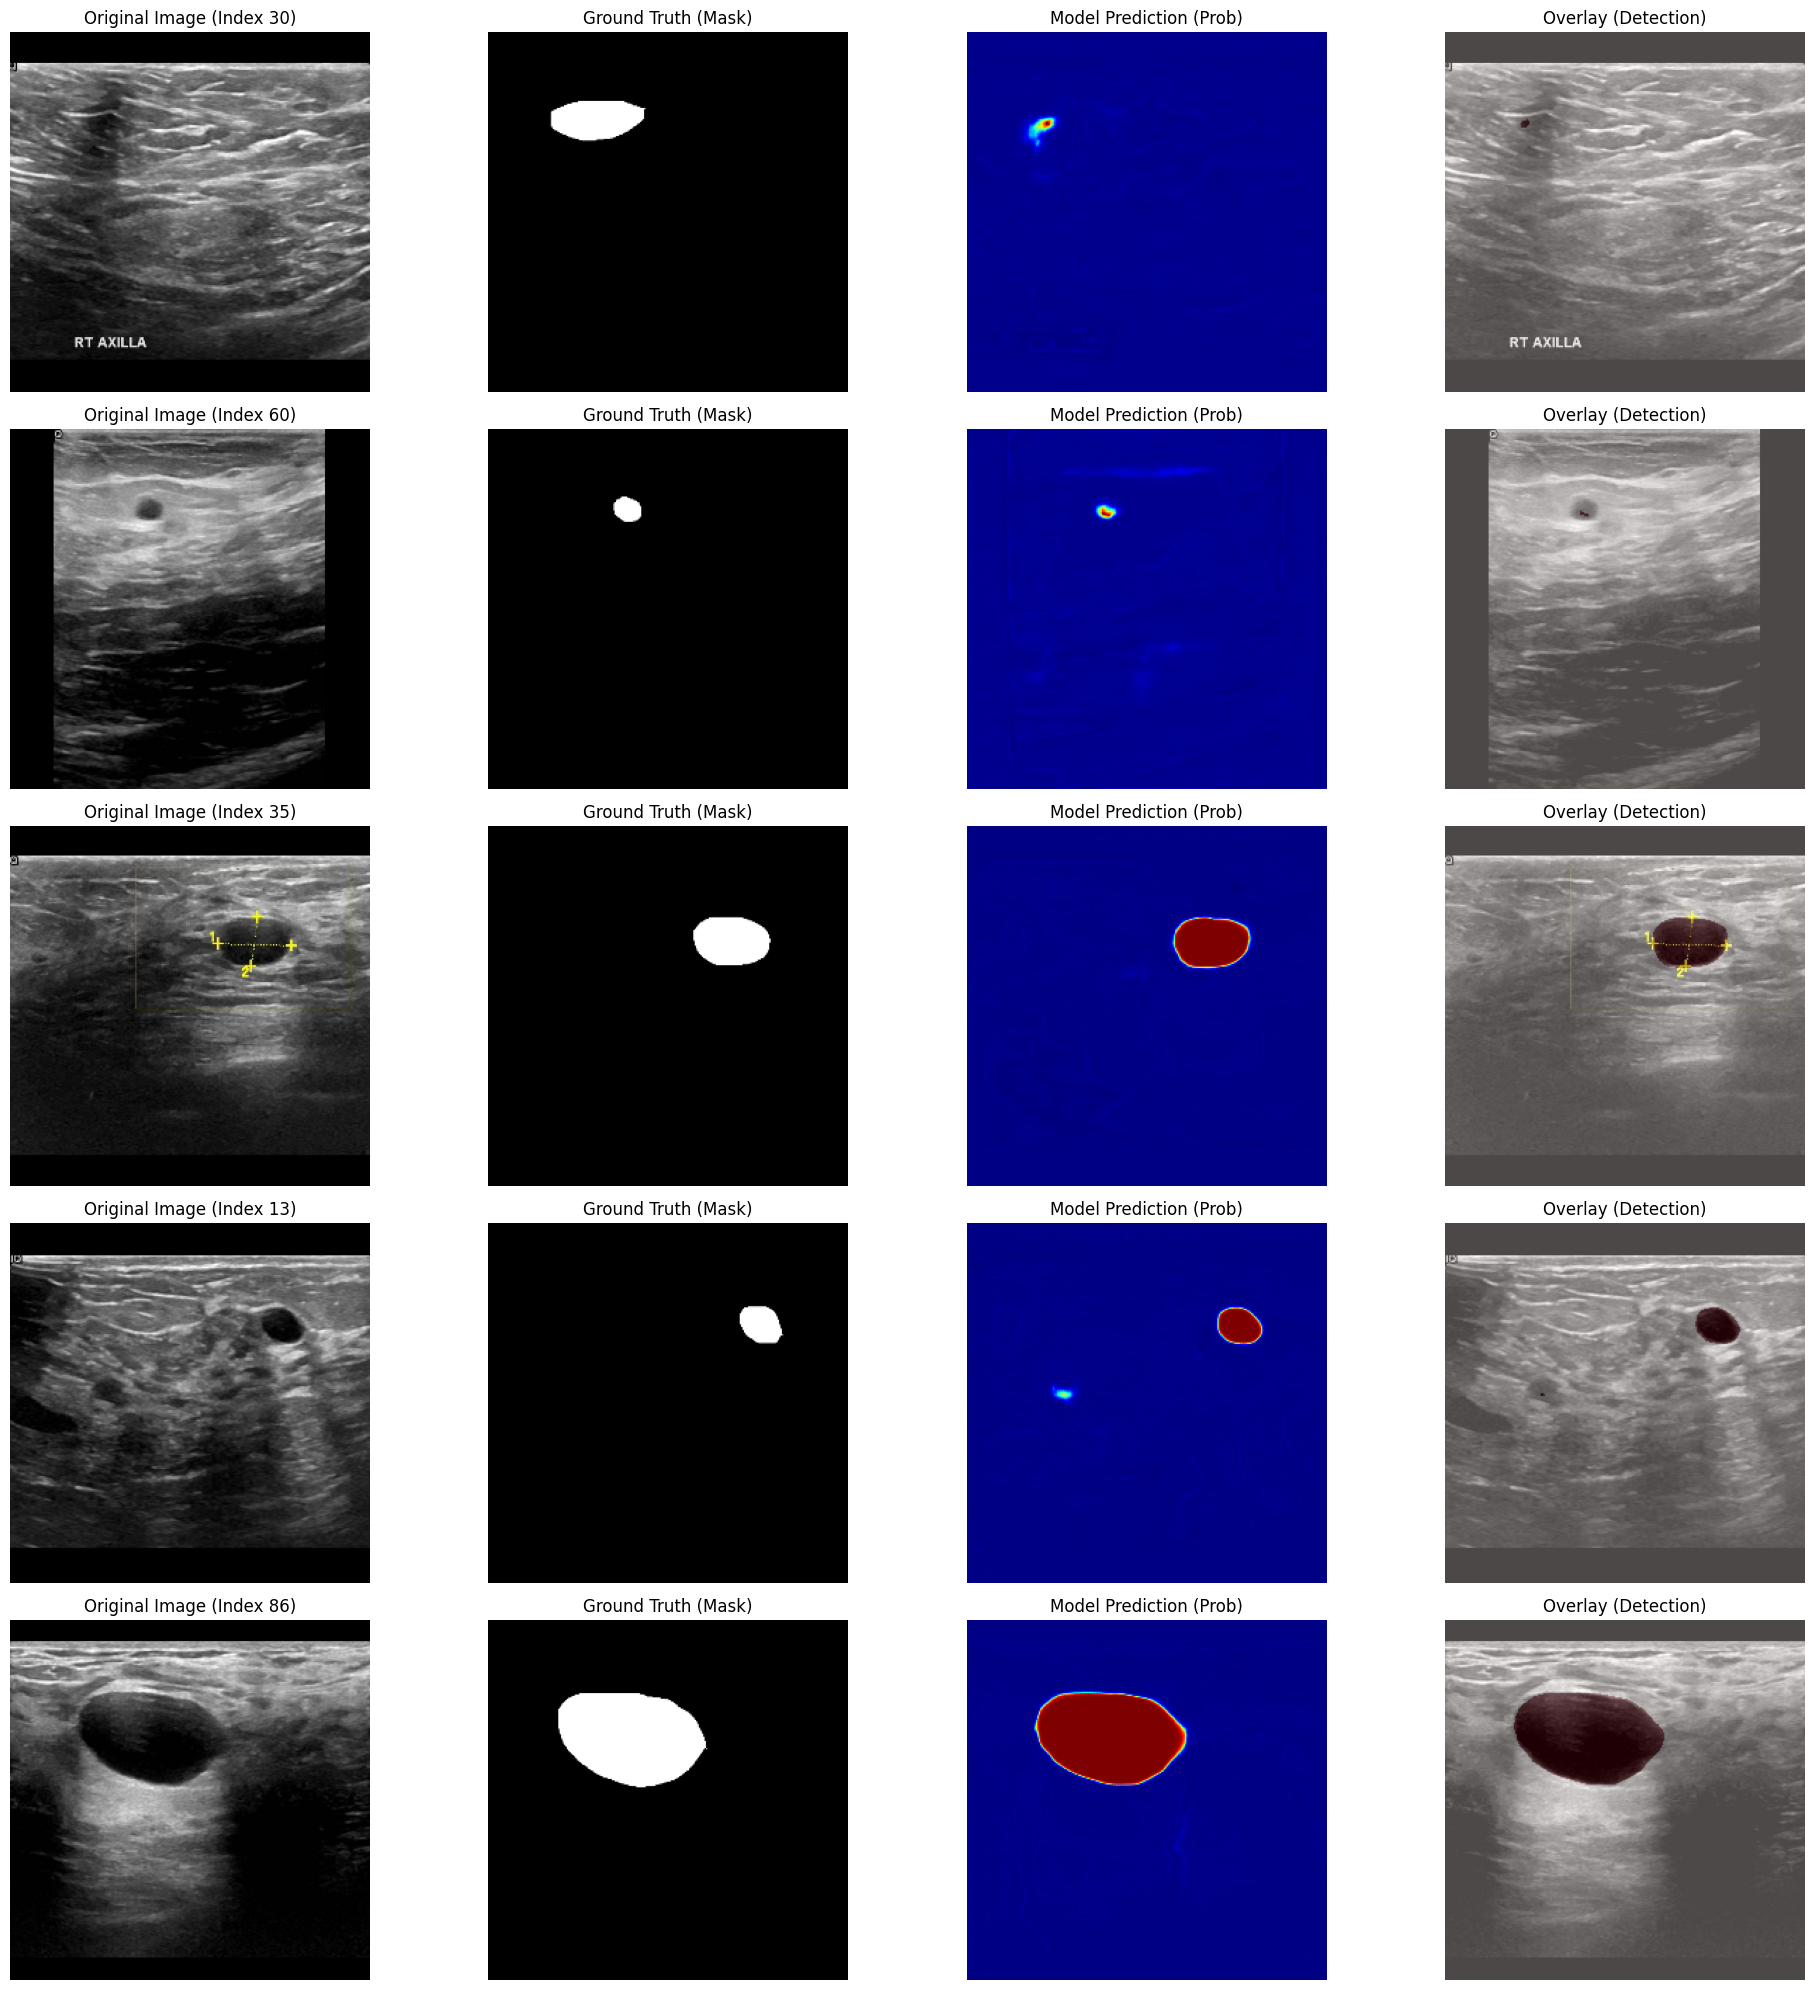

In [10]:
import random
def plot_random_test_results(model, X_test, y_test, num_samples=5):
    indices = random.sample(range(len(X_test)), num_samples)

    plt.figure(figsize=(20, num_samples * 4))

    for i, idx in enumerate(indices):
        img = X_test[idx]
        mask = y_test[idx]


        pred = model.predict(np.expand_dims(img, axis=0))
        pred_mask = (pred > 0.5).astype(np.uint8)

        plt.subplot(num_samples, 4, i*4 + 1)
        plt.imshow(img)
        plt.title(f"Original Image (Index {idx})")
        plt.axis('off')

        plt.subplot(num_samples, 4, i*4 + 2)
        plt.imshow(mask.squeeze(), cmap='gray')
        plt.title("Ground Truth (Mask)")
        plt.axis('off')

        plt.subplot(num_samples, 4, i*4 + 3)
        plt.imshow(pred.squeeze(), cmap='jet')
        plt.title("Model Prediction (Prob)")
        plt.axis('off')

        plt.subplot(num_samples, 4, i*4 + 4)
        plt.imshow(img)
        plt.imshow(pred_mask.squeeze(), cmap='Reds', alpha=0.3)
        plt.title("Overlay (Detection)")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


plot_random_test_results(model, X_test, y_test)